# Extra 2.2 — Chatbot com BERT e comparação com método clássico

**Aluno: Tiago Galhardo Avelar**

**Tema:** reconhecimento de intenções e chatbot bancário com **BERT-Mini (Transformer)**, usando o mesmo **BANKING77** do notebook clássico (TF-IDF + LinearSVC).

**Objetivos:** explicar tokenização contextual e *fine-tuning*; treinar e avaliar um BERT pré-treinado; integrar o classificador a respostas predefinidas; e comparar qualidade, erros e custo computacional com o chatbot clássico.

> **Importante:** BERT classifica a intenção, mas não gera livremente a resposta. Um gerenciador simples seleciona respostas previamente cadastradas.

O notebook registra dispositivo, quantidade real de exemplos, tempos e métricas para que as limitações da comparação sejam verificáveis.


## 1. Tokenização contextual e *fine-tuning*

O tokenizador WordPiece divide palavras conhecidas ou raras em unidades menores e converte cada unidade em um identificador. A sequência recebe tokens especiais, como `[CLS]` e `[SEP]`, além de uma máscara que diferencia conteúdo real de *padding*. Diferentemente do TF-IDF, a representação de um token em BERT é **contextual**: ela é recalculada pelas camadas de autoatenção considerando os demais tokens da frase. Assim, uma mesma palavra pode produzir vetores diferentes conforme o contexto.

No *fine-tuning*, carregamos pesos pré-treinados em grandes coleções de texto e adicionamos uma camada de classificação com 77 saídas. Todos os pesos são ajustados, com taxa de aprendizado pequena, para minimizar a perda de classificação do BANKING77. A época escolhida depende apenas do F1-macro de validação; o teste oficial é reservado para a avaliação final.

| Aspecto | TF-IDF + LinearSVC | BERT-Mini + classificador |
|---|---|---|
| Representação | Pesos de unigramas e bigramas | Tokens com representações contextuais |
| Aprendizado | Classificador linear treinado do zero | Rede pré-treinada ajustada + camada de 77 classes |
| Ordem e contexto | Limitados aos n-gramas configurados | Modelados pela autoatenção |
| Custo | Baixo em CPU | Maior; GPU é recomendada |
| Score | Margem do SVM | *Softmax* não necessariamente calibrado |
| Resposta | Catálogo predefinido | O mesmo catálogo predefinido |

Usaremos `google/bert_uncased_L-4_H-256_A-4`, uma variante compacta com quatro camadas, dimensão oculta 256 e quatro cabeças de atenção.


## 2. Preparação do ambiente

As versões são registradas como evidência de reprodutibilidade. As bibliotecas já estão disponíveis no ambiente de execução.


In [1]:
import importlib.metadata as metadata

for package in ['torch', 'transformers', 'scikit-learn', 'pandas', 'numpy']:
    print(f'{package}: {metadata.version(package)}')


torch: 2.14.0
transformers: 4.57.3
scikit-learn: 1.9.1
pandas: 3.1.0
numpy: 2.5.2


In [2]:
import os, time, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(min(8, os.cpu_count() or 1))

MODEL_NAME = 'google/bert_uncased_L-4_H-256_A-4'
MAX_LEN = 48
BATCH_SIZE = 32
EPOCHS = 8 if device.type == 'cpu' else 20
PATIENCE = 3
LEARNING_RATE = 5e-5 if device.type == 'cpu' else 3e-5
WARMUP_RATIO = 0.06
MIN_DELTA = 1e-4
CPU_EXAMPLES_PER_CLASS = 20

print('Dispositivo:', device, '| PyTorch:', torch.__version__)
print('Configuração:', {'max_length': MAX_LEN, 'batch_size': BATCH_SIZE,
                         'max_epochs': EPOCHS, 'learning_rate': LEARNING_RATE,
                         'patience': PATIENCE, 'seed': SEED})
if device.type == 'cpu':
    print('AVISO: treino BERT reduzido e estratificado na CPU; validação e teste permanecem completos.')


C:\workspace\fatec\aprendizagem_maquina\.notebook-deps\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu | PyTorch: 2.14.0+cpu
Configuração: {'max_length': 48, 'batch_size': 32, 'max_epochs': 8, 'learning_rate': 5e-05, 'patience': 3, 'seed': 42}
AVISO: treino BERT reduzido e estratificado na CPU; validação e teste permanecem completos.


## 3. Dataset BANKING77 e justiça experimental

Os CSVs oficiais são usados nos dois modelos. Preservamos o **teste oficial** e criamos validação estratificada de 15% com `random_state=42`. O SVM usa todo o treino restante. Quando não há GPU, o BERT usa 20 exemplos por intenção para manter a execução local viável; essa diferença é exibida e considerada nas conclusões.


In [3]:
BASE = 'https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data'
train_raw = pd.read_csv(f'{BASE}/train.csv')
test_df = pd.read_csv(f'{BASE}/test.csv')
assert {'text', 'category'}.issubset(train_raw.columns)

train_full_df, val_df = train_test_split(
    train_raw, test_size=0.15, random_state=SEED, stratify=train_raw['category']
)
train_full_df = train_full_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

if device.type == 'cpu':
    train_df = (train_full_df.groupby('category', group_keys=False)
                .sample(n=CPU_EXAMPLES_PER_CLASS, random_state=SEED)
                .sample(frac=1, random_state=SEED).reset_index(drop=True))
else:
    train_df = train_full_df.copy()

labels = sorted(train_raw['category'].unique())
label2id = {name: i for i, name in enumerate(labels)}
id2label = {i: name for name, i in label2id.items()}

split_summary = pd.DataFrame({
    'Divisão': ['Treino SVM', 'Treino BERT', 'Validação', 'Teste oficial'],
    'Exemplos': [len(train_full_df), len(train_df), len(val_df), len(test_df)],
    'Intenções': [train_full_df.category.nunique(), train_df.category.nunique(),
                  val_df.category.nunique(), test_df.category.nunique()]
})
display(split_summary)
display(train_df.sample(5, random_state=SEED))
assert len(labels) == 77 and train_df.category.nunique() == 77


,Divisão,Exemplos,Intenções
0,Treino SVM,8502,77
1,Treino BERT,1540,77
2,Validação,1501,77
3,Teste oficial,3080,77


,text,category
168,What method do you use for the exchange rate?,exchange_rate
1117,I'm not able to verify my identity.,unable_to_verify_identity
30,why top up is not working even if I got my Ame...,apple_pay_or_google_pay
185,What steps do I take to unblock my PIN?,pin_blocked
973,How do I find the PIN?,get_physical_card


## 4. Tokenização e tensores

O tokenizador WordPiece produz `input_ids`. A `attention_mask` marca tokens reais e *padding*. O preenchimento é dinâmico por minibatch e mensagens acima de `MAX_LEN` são truncadas, reduzindo memória e tempo.


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sample = 'I lost my bank card and need a replacement'
encoded_sample = tokenizer(sample, truncation=True, max_length=MAX_LEN)
print('Texto:', sample)
print('Tokens:', tokenizer.tokenize(sample))
print('IDs:', encoded_sample['input_ids'])

class BankingDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame['text'].tolist()
        self.targets = [label2id[x] for x in frame['category']]
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        encoded = tokenizer(self.texts[index], truncation=True, max_length=MAX_LEN)
        encoded['labels'] = self.targets[index]
        return encoded

from transformers import DataCollatorWithPadding
collator = DataCollatorWithPadding(tokenizer=tokenizer)
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(BankingDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collator, generator=generator)
val_loader = DataLoader(BankingDataset(val_df), batch_size=BATCH_SIZE * 2, shuffle=False,
                        collate_fn=collator)
test_loader = DataLoader(BankingDataset(test_df), batch_size=BATCH_SIZE * 2, shuffle=False,
                         collate_fn=collator)
print('Minibatches — treino:', len(train_loader), '| validação:', len(val_loader), '| teste:', len(test_loader))


Texto: I lost my bank card and need a replacement
Tokens: ['i', 'lost', 'my', 'bank', 'card', 'and', 'need', 'a', 'replacement']
IDs: [101, 1045, 2439, 2026, 2924, 4003, 1998, 2342, 1037, 6110, 102]
Minibatches — treino: 49 | validação: 24 | teste: 49


## 5. *Fine-tuning* do BERT-Mini

A camada de 77 classes é inicializada aleatoriamente e todo o modelo é ajustado com AdamW. O melhor estado é selecionado pelo F1-macro de validação. *Gradient clipping*, aquecimento e decaimento linear da taxa de aprendizado tornam o treinamento mais estável. O conjunto de teste não participa da escolha da época.


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-4_H-256_A-4 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Épocas máximas=8 | passos/época=49 | passos totais=392


Época 1: perda=4.3672, val acc=0.031, val F1-macro=0.007, LR=4.65e-05


Época 2: perda=4.3007, val acc=0.070, val F1-macro=0.037, LR=3.98e-05


Época 3: perda=4.1920, val acc=0.164, val F1-macro=0.125, LR=3.32e-05


...

Época 5: perda=3.9652, val acc=0.303, val F1-macro=0.269, LR=1.99e-05


Época 6: perda=3.8905, val acc=0.346, val F1-macro=0.318, LR=1.33e-05


Época 7: perda=3.8339, val acc=0.366, val F1-macro=0.337, LR=6.64e-06


Época 8: perda=3.7992, val acc=0.377, val F1-macro=0.350, LR=0.00e+00
Tempo de treinamento e validações: 227.2 s | Melhor época: 8 | Melhor F1-macro val: 0.3498


,epoch,loss_train,learning_rate,accuracy,precision_macro,recall_macro,f1_macro
0,1,4.36721,0.00005,0.03065,0.00454,0.02782,0.00697
1,2,4.30065,0.00004,0.06995,0.04471,0.06950,0.03661
2,3,4.19195,0.00003,0.16389,0.17686,0.17074,0.12503
3,4,4.06519,0.00003,0.23118,0.24197,0.23864,0.19164
4,5,3.96522,0.00002,0.30313,0.35237,0.31359,0.26905
5,6,3.89048,0.00001,0.34644,0.40473,0.36005,0.31782
6,7,3.83390,0.00001,0.36576,0.41864,0.37796,0.33733
7,8,3.79918,0.00000,0.37708,0.43816,0.38985,0.34979


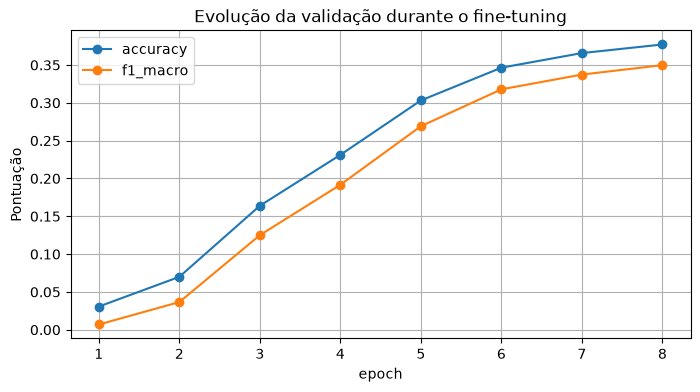

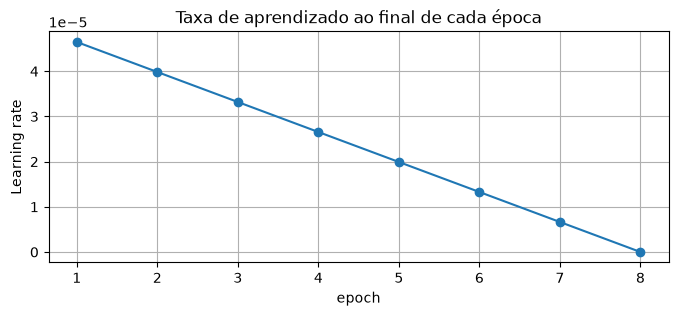

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id2label, label2id=label2id
).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
total_steps = max(1, EPOCHS * len(train_loader))
warmup_steps = min(total_steps, int(total_steps * WARMUP_RATIO))
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps
)
print(f'Épocas máximas={EPOCHS} | passos/época={len(train_loader)} | passos totais={total_steps}')

def predict_loader(loader):
    model.eval()
    predictions, targets, all_logits = [], [], []
    with torch.inference_mode():
        for batch in loader:
            target = batch['labels']
            inputs = {key: value.to(device) for key, value in batch.items() if key != 'labels'}
            logits = model(**inputs).logits.detach().cpu()
            predictions.extend(logits.argmax(dim=1).tolist())
            targets.extend(target.tolist())
            all_logits.append(logits)
    return np.asarray(targets), np.asarray(predictions), torch.cat(all_logits).numpy()

def calculate_metrics(targets, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        targets, predictions, average='macro', zero_division=0
    )
    return {'accuracy': accuracy_score(targets, predictions),
            'precision_macro': precision, 'recall_macro': recall, 'f1_macro': f1}

history = []
best_f1, best_epoch, best_state, no_improvement = -1.0, 0, None, 0
training_start = time.perf_counter()
for epoch in range(EPOCHS):
    model.train()
    losses = []
    for batch in train_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        loss = model(**batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
    validation_targets, validation_predictions, _ = predict_loader(val_loader)
    current = calculate_metrics(validation_targets, validation_predictions)
    current_lr = scheduler.get_last_lr()[0]
    history.append({'epoch': epoch + 1, 'loss_train': np.mean(losses),
                    'learning_rate': current_lr, **current})
    if current['f1_macro'] > best_f1 + MIN_DELTA:
        best_f1, best_epoch = current['f1_macro'], epoch + 1
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        no_improvement = 0
    else:
        no_improvement += 1
    print(f'Época {epoch + 1}: perda={np.mean(losses):.4f}, '
          f'val acc={current["accuracy"]:.3f}, val F1-macro={current["f1_macro"]:.3f}, '
          f'LR={current_lr:.2e}')
    if no_improvement >= PATIENCE:
        print(f'Early stopping: {PATIENCE} épocas consecutivas sem melhora relevante.')
        break

train_seconds = time.perf_counter() - training_start
model.load_state_dict(best_state)
model.to(device)
history_df = pd.DataFrame(history)
print(f'Tempo de treinamento e validações: {train_seconds:.1f} s | '
      f'Melhor época: {best_epoch} | Melhor F1-macro val: {best_f1:.4f}')
display(history_df.round(5))

history_df.plot(x='epoch', y=['accuracy', 'f1_macro'], marker='o', figsize=(8, 4), grid=True)
plt.title('Evolução da validação durante o fine-tuning')
plt.ylabel('Pontuação')
plt.show()

history_df.plot(x='epoch', y='learning_rate', marker='o', figsize=(8, 3), grid=True, legend=False)
plt.title('Taxa de aprendizado ao final de cada época')
plt.ylabel('Learning rate')
plt.show()


## 6. Avaliação final

As mesmas métricas do modelo clássico são calculadas em validação e no teste oficial. A tabela também registra o custo de inferência por mensagem neste hardware.


In [6]:
start = time.perf_counter()
y_val, p_val, logits_val = predict_loader(val_loader)
val_seconds = time.perf_counter() - start
start = time.perf_counter()
y_test, p_test, logits_test = predict_loader(test_loader)
test_seconds = time.perf_counter() - start

resultados = pd.DataFrame([
    {'divisao': 'validação', **calculate_metrics(y_val, p_val),
     'tempo_s': val_seconds, 'ms_por_mensagem': 1000 * val_seconds / len(y_val)},
    {'divisao': 'teste', **calculate_metrics(y_test, p_test),
     'tempo_s': test_seconds, 'ms_por_mensagem': 1000 * test_seconds / len(y_test)}
])
display(resultados.round(4))
print('Dispositivo:', device, '| treino BERT:', len(train_df), '| treino SVM:', len(train_full_df),
      '| épocas executadas:', len(history))
assert len(y_test) == len(test_df) == 3080


,divisao,accuracy,precision_macro,recall_macro,f1_macro,tempo_s,ms_por_mensagem
0,validação,0.3771,0.4382,0.3899,0.3498,5.1650,3.4411
1,teste,0.3685,0.4512,0.3685,0.3375,7.9357,2.5765


Dispositivo: cpu | treino BERT: 1540 | treino SVM: 8502 | épocas executadas: 8


### 6.1. Análise de erros

A matriz completa contém as 77 classes. Para facilitar a leitura, mostramos também as dez intenções com mais erros e preservamos uma coluna “Outras classes”, evitando ocultar previsões direcionadas para fora do recorte.


Erros no teste: 1945 de 3080 mensagens (63.1%)


,text,verdadeira,prevista
0,How do I locate my card?,card_arrival,activate_my_card
2,I ordered a card but it has not arrived. Help ...,card_arrival,card_swallowed
3,Is there a way to know when my card will arrive?,card_arrival,card_swallowed
4,My card has not arrived yet.,card_arrival,card_swallowed
5,When will I get my card?,card_arrival,card_swallowed
6,Do you know if there is a tracking number for ...,card_arrival,visa_or_mastercard
7,i have not received my card,card_arrival,card_swallowed
8,still waiting on that card,card_arrival,card_swallowed
10,How do I track my card?,card_arrival,card_acceptance
11,How long does a card delivery take?,card_arrival,getting_spare_card


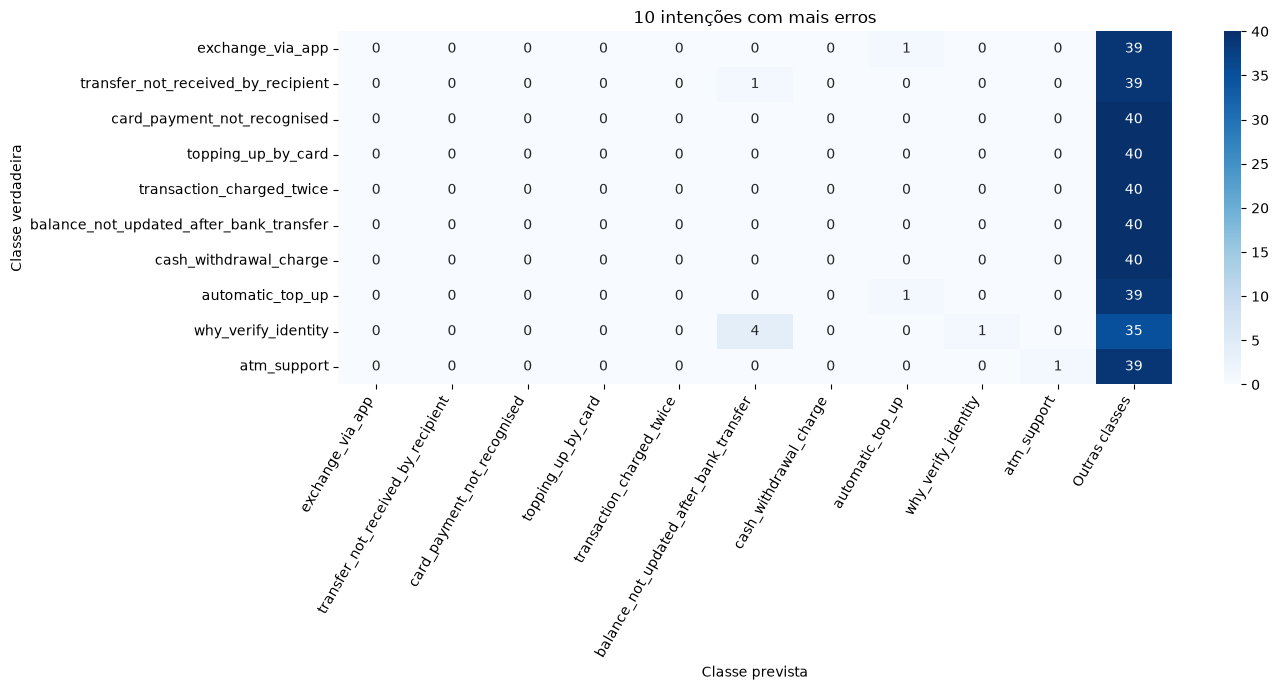

,verdadeira,prevista,quantidade
0,automatic_top_up,top_up_limits,25
1,top_up_failed,pending_top_up,25
2,balance_not_updated_after_bank_transfer,transfer_timing,24
3,cash_withdrawal_charge,wrong_amount_of_cash_received,23
4,apple_pay_or_google_pay,top_up_limits,22
5,pin_blocked,change_pin,19
6,exchange_charge,fiat_currency_support,19
7,lost_or_stolen_card,card_swallowed,18
8,receiving_money,supported_cards_and_currencies,17
9,why_verify_identity,verify_my_identity,17


In [7]:
import seaborn as sns

errors = test_df.copy()
errors['verdadeira'] = [id2label[index] for index in y_test]
errors['prevista'] = [id2label[index] for index in p_test]
errors['erro'] = errors['verdadeira'] != errors['prevista']
print(f'Erros no teste: {errors.erro.sum()} de {len(errors)} mensagens ({errors.erro.mean():.1%})')
display(errors.loc[errors.erro, ['text', 'verdadeira', 'prevista']].head(10))

confusion_full = confusion_matrix(y_test, p_test, labels=range(len(labels)))
assert confusion_full.shape == (77, 77) and confusion_full.sum() == len(y_test)

worst_labels = errors.loc[errors.erro, 'verdadeira'].value_counts().head(10).index.tolist()
subset = errors[errors['verdadeira'].isin(worst_labels)].copy()
subset['coluna_predicao'] = subset['prevista'].where(
    subset['prevista'].isin(worst_labels), 'Outras classes'
)
small_confusion = pd.crosstab(subset['verdadeira'], subset['coluna_predicao'])
small_confusion = small_confusion.reindex(
    index=worst_labels, columns=worst_labels + ['Outras classes'], fill_value=0
)
fig, axis = plt.subplots(figsize=(14, 7))
sns.heatmap(small_confusion, annot=True, fmt='d', cmap='Blues', ax=axis)
axis.set(title='10 intenções com mais erros', xlabel='Classe prevista', ylabel='Classe verdadeira')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

confusion_pairs = (errors.loc[errors.erro].groupby(['verdadeira', 'prevista'])
                   .size().sort_values(ascending=False).head(15)
                   .rename('quantidade').reset_index())
display(confusion_pairs)


## 7. Chatbot com respostas predefinidas e fallback

O BERT prevê a intenção e o catálogo seleciona a resposta. O fallback usa o percentil 5 dos maiores *scores softmax* entre os acertos de validação. É uma heurística didática: *softmax* alto não é garantia de correção nem de pertencimento ao domínio.


In [8]:
responses = {
    'lost_or_stolen_card': 'Please freeze your card in the app and contact support to request a replacement.',
    'card_not_working': 'Please verify the card status in your app and try again.',
    'card_arrival': 'You can check the delivery status of your card in the app.',
    'change_pin': 'You can change your PIN using the card settings in the app.',
    'cash_withdrawal_charge': 'Check the withdrawal fee details in your transaction history.',
    'pending_transfer': 'Check the transfer status in your app.',
    'cancel_transfer': 'Please contact support promptly to check whether the transfer can still be canceled.',
    'beneficiary_not_allowed': 'Review the beneficiary details and contact support if the restriction remains.',
    'verify_my_identity': 'Open the verification section and follow the identification instructions.',
    'card_payment_wrong_exchange_rate': 'Review the exchange-rate details in your transaction history.'
}
responses = {key: value for key, value in responses.items() if key in label2id}
validation_confidence = torch.softmax(torch.tensor(logits_val), dim=1).numpy().max(axis=1)
correct_confidence = validation_confidence[p_val == y_val]
bert_threshold = float(np.quantile(correct_confidence, 0.05)) if len(correct_confidence) else 0.5
print('Limiar BERT:', round(bert_threshold, 3), '| Respostas específicas:', len(responses))

class BertChatbot:
    def __init__(self, trained_model, trained_tokenizer, response_map, threshold):
        self.model = trained_model
        self.tokenizer = trained_tokenizer
        self.response_map = response_map
        self.threshold = threshold
    def respond(self, message):
        if not isinstance(message, str) or not message.strip():
            return {'message': message, 'intent': None, 'score': 0.0, 'fallback': True,
                    'response': 'Please type a banking question.'}
        self.model.eval()
        inputs = self.tokenizer(message, return_tensors='pt', truncation=True,
                                max_length=MAX_LEN).to(device)
        with torch.inference_mode():
            logits = self.model(**inputs).logits[0]
            probabilities = torch.softmax(logits, dim=-1)
            score, index = probabilities.max(dim=-1)
        intent = id2label[int(index)]
        confidence = float(score)
        fallback = confidence < self.threshold
        answer = ('I am not sure what you mean. Could you rephrase your banking question?'
                  if fallback else self.response_map.get(
                      intent, f'I understood your request as: {intent.replace("_", " ")}. '
                              'Please contact support for further assistance.'))
        return {'message': message, 'intent': intent, 'score': confidence,
                'fallback': fallback, 'response': answer}

bot = BertChatbot(model, tokenizer, responses, bert_threshold)
demo_questions = ['I lost my card', 'My transfer is still pending',
                  'Tell me a joke', 'My PIN is not working']
display(pd.DataFrame([bot.respond(question) for question in demo_questions]))


Limiar BERT: 0.023 | Respostas específicas: 10


,message,intent,score,fallback,response
0,I lost my card,card_swallowed,0.028207,False,I understood your request as: card swallowed. ...
1,My transfer is still pending,pending_transfer,0.025459,False,Check the transfer status in your app.
2,Tell me a joke,getting_virtual_card,0.022119,True,I am not sure what you mean. Could you rephras...
3,My PIN is not working,pending_top_up,0.023203,False,I understood your request as: pending top up. ...


### 7.1. Converse com o chatbot

O modelo foi treinado em inglês. A função abaixo pode ser chamada, por exemplo, com `chat('My card is missing')`.


In [9]:
def chat(message):
    result = bot.respond(message)
    print('Você:', result['message'])
    print('Intenção:', result['intent'])
    print('Score softmax não calibrado:', round(result['score'], 3))
    print('Fallback:', result['fallback'])
    print('Chatbot:', result['response'])
    return result

chat('My card is missing. What should I do?')


Você: My card is missing. What should I do?
Intenção: card_swallowed
Score softmax não calibrado: 0.029
Fallback: False
Chatbot: I understood your request as: card swallowed. Please contact support for further assistance.


{'message': 'My card is missing. What should I do?',
 'intent': 'card_swallowed',
 'score': 0.028853213414549828,
 'fallback': False,
 'response': 'I understood your request as: card swallowed. Please contact support for further assistance.'}

## 8. Atividades — comparação crítica entre BERT e TF-IDF + SVM

Para uma comparação verificável, o SVM é treinado abaixo no mesmo *split* e avaliado no mesmo teste oficial. A diferença no tamanho do treino BERT em CPU é explicitamente registrada.


In [10]:
svm_model = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                              max_df=0.98, sublinear_tf=True)),
    ('classifier', LinearSVC(C=1.0, random_state=SEED))
])
svm_start = time.perf_counter()
svm_model.fit(train_full_df['text'], train_full_df['category'])
svm_train_seconds = time.perf_counter() - svm_start

svm_inference_start = time.perf_counter()
svm_test_prediction = svm_model.predict(test_df['text'])
svm_inference_seconds = time.perf_counter() - svm_inference_start
svm_precision, svm_recall, svm_f1, _ = precision_recall_fscore_support(
    test_df['category'], svm_test_prediction, average='macro', zero_division=0
)
svm_metrics = {
    'accuracy': accuracy_score(test_df['category'], svm_test_prediction),
    'precision_macro': svm_precision,
    'recall_macro': svm_recall,
    'f1_macro': svm_f1,
    'tempo_treino_s': svm_train_seconds,
    'ms_por_mensagem': 1000 * svm_inference_seconds / len(test_df)
}
bert_test = resultados.set_index('divisao').loc['teste']
comparison = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision macro', 'Recall macro', 'F1 macro',
                'Tempo de treino (s)', 'Inferência (ms/mensagem)'],
    'SVM clássico': [svm_metrics['accuracy'], svm_metrics['precision_macro'],
                    svm_metrics['recall_macro'], svm_metrics['f1_macro'],
                    svm_metrics['tempo_treino_s'], svm_metrics['ms_por_mensagem']],
    'BERT-Mini': [bert_test['accuracy'], bert_test['precision_macro'],
                  bert_test['recall_macro'], bert_test['f1_macro'],
                  train_seconds, bert_test['ms_por_mensagem']]
})
display(comparison.round(4))
winner = 'BERT-Mini' if bert_test['f1_macro'] > svm_metrics['f1_macro'] else 'SVM clássico'
print('Maior F1-macro no teste:', winner)
print('Interpretação: a diferença de qualidade deve ser analisada junto com tempo, hardware e quantidade de treino.')


,Métrica,SVM clássico,BERT-Mini
0,Accuracy,0.8841,0.3685
1,Precision macro,0.8880,0.4512
2,Recall macro,0.8841,0.3685
3,F1 macro,0.8842,0.3375
4,Tempo de treino (s),0.7502,227.2468
5,Inferência (ms/mensagem),0.0147,2.5765


Maior F1-macro no teste: SVM clássico
Interpretação: a diferença de qualidade deve ser analisada junto com tempo, hardware e quantidade de treino.


In [11]:
# Limiar do SVM definido exclusivamente na validação.
svm_val_prediction = svm_model.predict(val_df['text'])
svm_val_decision = svm_model.decision_function(val_df['text'])
svm_val_margin = svm_val_decision.max(axis=1)
svm_correct_margin = svm_val_margin[svm_val_prediction == val_df['category'].to_numpy()]
svm_threshold = float(np.quantile(svm_correct_margin, 0.05))

def svm_respond(message):
    decision = svm_model.decision_function([message])[0]
    index = int(np.argmax(decision))
    intent = svm_model.classes_[index]
    score = float(decision[index])
    return {'intent': intent, 'score': score, 'fallback': score < svm_threshold}

comparison_messages = [
    'I cannot find my bank card anywhere.',
    'I need to change my card PIN.',
    'Why has my transfer not arrived?',
    'My caard is not workng.',
    'Can you tell me a joke?'
]
message_rows = []
for message in comparison_messages:
    bert_result = bot.respond(message)
    svm_result = svm_respond(message)
    message_rows.append({
        'Mensagem': message,
        'BERT intenção': bert_result['intent'], 'BERT score': bert_result['score'],
        'BERT fallback': bert_result['fallback'],
        'SVM intenção': svm_result['intent'], 'SVM margem': svm_result['score'],
        'SVM fallback': svm_result['fallback']
    })
display(pd.DataFrame(message_rows).round(3))


,Mensagem,BERT intenção,BERT score,BERT fallback,SVM intenção,SVM margem,SVM fallback
0,I cannot find my bank card anywhere.,get_physical_card,0.025,False,get_physical_card,-0.622,True
1,I need to change my card PIN.,change_pin,0.029,False,change_pin,1.014,False
2,Why has my transfer not arrived?,cancel_transfer,0.025,False,transfer_not_received_by_recipient,0.312,False
3,My caard is not workng.,pending_top_up,0.025,False,beneficiary_not_allowed,-0.661,True
4,Can you tell me a joke?,getting_virtual_card,0.027,False,get_disposable_virtual_card,-0.661,True


### 8.1. Três erros específicos e suas causas prováveis

Selecionamos automaticamente uma mensagem real dos três pares de confusão mais frequentes do BERT. Isso evita exemplos inventados e relaciona a explicação aos resultados efetivamente observados.


In [12]:
top_three_pairs = confusion_pairs.head(3)
error_examples = []
for _, pair in top_three_pairs.iterrows():
    example = errors[(errors['verdadeira'] == pair['verdadeira']) &
                     (errors['prevista'] == pair['prevista'])].iloc[0]
    error_examples.append({
        'Mensagem': example['text'],
        'Correta': pair['verdadeira'],
        'Prevista': pair['prevista'],
        'Ocorrências do par': int(pair['quantidade']),
        'Causa provável': ('As intenções compartilham vocabulário bancário e diferem por estado, '
                           'finalidade ou participante; a frase curta pode omitir essa pista.')
    })
error_examples_df = pd.DataFrame(error_examples)
display(error_examples_df)
print('Limitação observada: contexto ajuda, mas classes semanticamente próximas e mensagens curtas '
      'continuam ambíguas. Mais exemplos contrastivos podem ensinar as fronteiras entre intenções.')
assert len(error_examples_df) == 3


,Mensagem,Correta,Prevista,Ocorrências do par,Causa provável
0,Is there a limit when using auto top-up?,automatic_top_up,top_up_limits,25,As intenções compartilham vocabulário bancário...
1,The app denied my topped up.,top_up_failed,pending_top_up,25,As intenções compartilham vocabulário bancário...
2,I made a transfer a few hours ago from a UK ba...,balance_not_updated_after_bank_transfer,transfer_timing,24,As intenções compartilham vocabulário bancário...


Limitação observada: contexto ajuda, mas classes semanticamente próximas e mensagens curtas continuam ambíguas. Mais exemplos contrastivos podem ensinar as fronteiras entre intenções.


### 8.2. Custo, justiça experimental e uso em produção

O quadro abaixo explicita o hardware, o número de exemplos e o conjunto de teste. Comparações de tempo só são justas quando esses fatores são considerados.


In [13]:
experimental_audit = pd.DataFrame([
    {'Modelo': 'TF-IDF + LinearSVC', 'Hardware': 'CPU',
     'Exemplos de treino': len(train_full_df), 'Teste oficial': len(test_df),
     'Tempo treino (s)': svm_train_seconds,
     'Inferência (ms/msg)': svm_metrics['ms_por_mensagem']},
    {'Modelo': 'BERT-Mini', 'Hardware': str(device).upper(),
     'Exemplos de treino': len(train_df), 'Teste oficial': len(test_df),
     'Tempo treino (s)': train_seconds,
     'Inferência (ms/msg)': bert_test['ms_por_mensagem']}
])
display(experimental_audit.round(3))
print('SVM é preferível quando há CPU limitada, baixa latência, necessidade de interpretação lexical '
      'ou atualização frequente. BERT é atraente quando ganhos contextuais justificam memória, energia '
      'e latência maiores. Nesta execução em CPU, o BERT usa menos exemplos; portanto, qualidade e custo '
      'não constituem uma comparação controlada de arquitetura.')


,Modelo,Hardware,Exemplos de treino,Teste oficial,Tempo treino (s),Inferência (ms/msg)
0,TF-IDF + LinearSVC,CPU,8502,3080,0.750,0.015
1,BERT-Mini,CPU,1540,3080,227.247,2.577


SVM é preferível quando há CPU limitada, baixa latência, necessidade de interpretação lexical ou atualização frequente. BERT é atraente quando ganhos contextuais justificam memória, energia e latência maiores. Nesta execução em CPU, o BERT usa menos exemplos; portanto, qualidade e custo não constituem uma comparação controlada de arquitetura.


### 8.3. Fallback e robustez fora do domínio

Testamos exatamente as mesmas cinco mensagens não bancárias nos dois classificadores.


In [14]:
out_of_domain = [
    'What is the best pasta recipe?',
    'Tell me a joke about dinosaurs.',
    'Will it rain tomorrow?',
    'Explain quantum entanglement.',
    'Who won the football match?'
]
ood_rows = []
for message in out_of_domain:
    bert_result = bot.respond(message)
    svm_result = svm_respond(message)
    ood_rows.append({
        'Mensagem': message,
        'BERT intenção': bert_result['intent'], 'BERT score': bert_result['score'],
        'BERT rejeitou': bert_result['fallback'],
        'SVM intenção': svm_result['intent'], 'SVM margem': svm_result['score'],
        'SVM rejeitou': svm_result['fallback']
    })
ood_df = pd.DataFrame(ood_rows)
display(ood_df.round(3))
print(f'BERT rejeitou {ood_df["BERT rejeitou"].sum()}/5; '
      f'SVM rejeitou {ood_df["SVM rejeitou"].sum()}/5 mensagens fora do domínio.')
print('Conclusão: softmax e margem são scores relativos às classes conhecidas. Nenhum deles modela '
      'explicitamente uma classe desconhecida; por isso podem ficar altos em entradas sem sentido. '
      'Produção exige dados OOD, calibração e/ou um detector separado.')


,Mensagem,BERT intenção,BERT score,BERT rejeitou,SVM intenção,SVM margem,SVM rejeitou
0,What is the best pasta recipe?,atm_support,0.021,True,exchange_rate,-0.485,True
1,Tell me a joke about dinosaurs.,card_acceptance,0.022,True,get_disposable_virtual_card,-0.637,True
2,Will it rain tomorrow?,automatic_top_up,0.021,True,cancel_transfer,-0.686,True
3,Explain quantum entanglement.,transfer_into_account,0.024,False,pending_cash_withdrawal,-0.717,True
4,Who won the football match?,top_up_reverted,0.022,True,verify_source_of_funds,-0.781,True


BERT rejeitou 4/5; SVM rejeitou 5/5 mensagens fora do domínio.
Conclusão: softmax e margem são scores relativos às classes conhecidas. Nenhum deles modela explicitamente uma classe desconhecida; por isso podem ficar altos em entradas sem sentido. Produção exige dados OOD, calibração e/ou um detector separado.


### 8.4. Épocas, convergência e scheduler

A época escolhida vem exclusivamente da validação. O teste oficial não influencia o checkpoint.


In [15]:
stopped_early = len(history) < EPOCHS
print('Melhor época:', best_epoch)
print('Épocas executadas:', len(history), 'de', EPOCHS)
print('Motivo do término:', 'early stopping' if stopped_early else 'limite máximo de épocas')
print(f'F1-macro — BERT: {bert_test["f1_macro"]:.4f} | SVM: {svm_metrics["f1_macro"]:.4f}')
print('Aumentar épocas não garante generalização: após o melhor ponto, a perda de treino pode cair '
      'enquanto o F1 de validação estagna ou piora. O scheduler reduz a taxa de aprendizado, mas não '
      'elimina overfitting; por isso preservamos o melhor checkpoint de validação.')


Melhor época: 8
Épocas executadas: 8 de 8
Motivo do término: limite máximo de épocas
F1-macro — BERT: 0.3375 | SVM: 0.8842
Aumentar épocas não garante generalização: após o melhor ponto, a perda de treino pode cair enquanto o F1 de validação estagna ou piora. O scheduler reduz a taxa de aprendizado, mas não elimina overfitting; por isso preservamos o melhor checkpoint de validação.


## 9. Conclusões e limitações

- O BERT representa tokens conforme o contexto e é ajustado para as 77 intenções; o SVM depende de pesos lexicais de n-gramas.
- Nesta máquina sem GPU, o BERT foi treinado com subconjunto estratificado, enquanto o SVM usou o treino completo. A tabela de auditoria impede interpretar a diferença observada como uma comparação perfeitamente controlada.
- Ambos continuam sendo classificadores de domínio fechado: associam uma intenção a uma resposta fixa e não conduzem uma conversa aberta.
- Mensagens ambíguas, classes semanticamente próximas, erros ortográficos e entradas fora do domínio continuam difíceis.
- Os fallbacks por *softmax* ou margem são heurísticos. Uma implantação real precisa de calibração, exemplos fora do domínio, monitoramento, privacidade e encaminhamento seguro para atendimento humano.


## 10. Referências

- Casanueva et al. (2020), *Efficient Intent Detection with Dual Sentence Encoders* — BANKING77.
- Devlin et al. (2019), *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*.
- Turc et al. (2019), *Well-Read Students Learn Better: On the Importance of Pre-training Compact Models*.
- [Dataset BANKING77 — PolyAI](https://github.com/PolyAI-LDN/task-specific-datasets).
- [BERT-Mini — Hugging Face Model Hub](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4).
- [Transformers — documentação](https://huggingface.co/docs/transformers/).
- [PyTorch — documentação](https://pytorch.org/docs/stable/).
- [Scikit-learn — documentação](https://scikit-learn.org/stable/).


# Comentários

---
**Comentários:**

Ferramenta: OpenAI Codex (modelo GPT-5)

Utilização: Utilizado como apoio para interpretar e adaptar o notebook-modelo, estruturar o código de treinamento e avaliação, implementar as comparações entre BERT e SVM, revisar a análise crítica e validar as evidências executadas.

Ferramenta: Hugging Face Transformers

Utilização: Utilizado para carregar o tokenizador WordPiece, o BERT-Mini pré-treinado e o scheduler do fine-tuning.

Ferramenta: PyTorch

Utilização: Utilizado para minibatches, treinamento, avaliação e inferência da rede neural.

Ferramenta: Scikit-learn

Utilização: Utilizado para divisão estratificada, métricas, TF-IDF e LinearSVC do chatbot clássico.

Ferramenta: pandas, NumPy, Matplotlib e Seaborn

Utilização: Utilizados para manipulação dos dados, cálculos, tabelas e visualizações.
---


In [16]:
assert len(labels) == 77
assert len(y_test) == 3080
assert not resultados.isna().any().any()
assert not comparison.isna().any().any()
assert len(error_examples_df) == 3
assert len(ood_df) == 5
print('Notebook Extra 2.2 concluído, executado e validado.')


Notebook Extra 2.2 concluído, executado e validado.
